In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

art = Path("../artifacts")
fig_dir = Path("../reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8985"

def save(name):
    plt.tight_layout()
    plt.savefig(fig_dir / name, dpi=150, bbox_inches="tight")   # before show()
    plt.show()

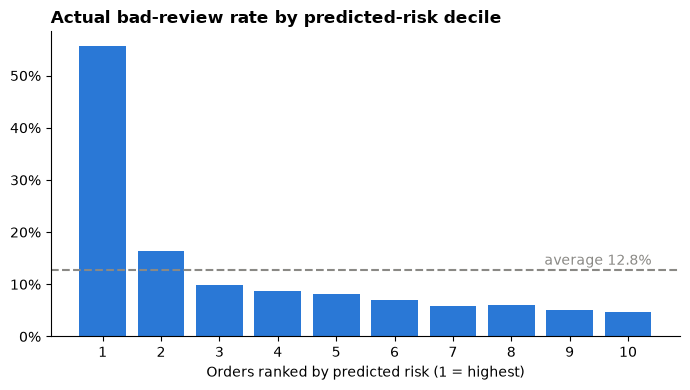

In [8]:
#Bad-review lift by decile
lf = pd.read_csv(art / "bad_review_lift.csv")
base = lf["bad"].sum() / lf["orders"].sum()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(lf["decile"], lf["rate"], color=BLUE)
ax.axhline(base, color=GRAY, ls="--")
ax.text(10.4, base + 0.01, f"average {base:.1%}", ha="right", color=GRAY)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Orders ranked by predicted risk (1 = highest)")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Actual bad-review rate by predicted-risk decile", loc="left", fontweight="bold")
save("06_bad_review_lift.png")

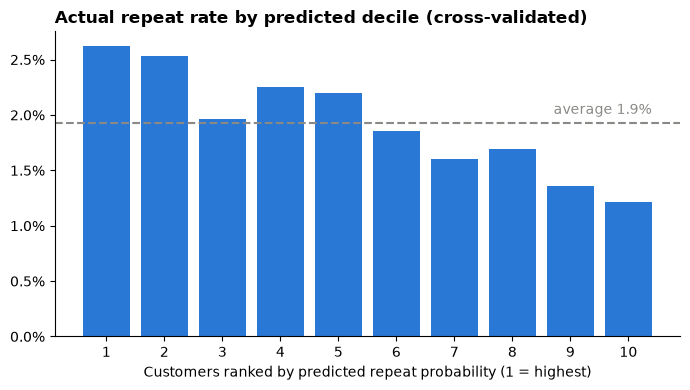

In [9]:
#Repeat-purchase lift by decile
cl = pd.read_csv(art / "churn_lift.csv")
base = cl["repeaters"].sum() / cl["customers"].sum()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(cl["decile"], cl["rate"], color=BLUE)
ax.axhline(base, color=GRAY, ls="--")
ax.text(10.4, base + 0.0008, f"average {base:.1%}", ha="right", color=GRAY)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Customers ranked by predicted repeat probability (1 = highest)")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax.set_title("Actual repeat rate by predicted decile (cross-validated)", loc="left", fontweight="bold")
save("07_repeat_lift.png")

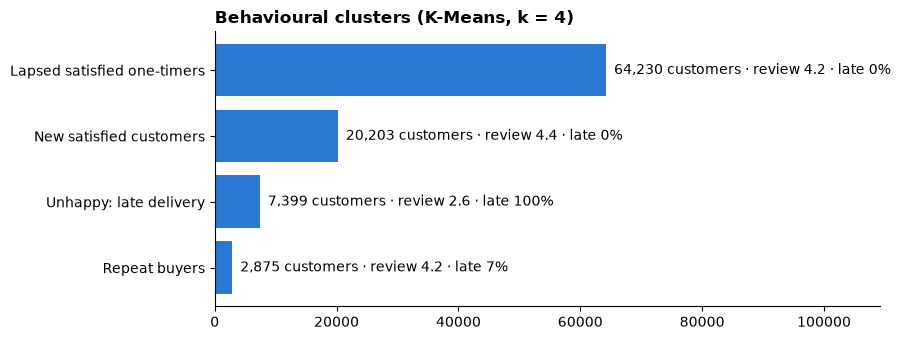

In [10]:
#Customer clusters
cp = pd.read_csv(art / "cluster_profile.csv").sort_values("customers")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(cp["cluster_name"], cp["customers"], color=BLUE)
for y, (n, r, l) in enumerate(zip(cp["customers"], cp["avg_review"], cp["late_share"])):
    ax.text(n, y, f"  {n:,} customers · review {r:.1f} · late {l:.0%}", va="center")
ax.set_xlim(0, cp["customers"].max() * 1.7)
ax.set_title("Behavioural clusters (K-Means, k = 4)", loc="left", fontweight="bold")
save("08_clusters.png")

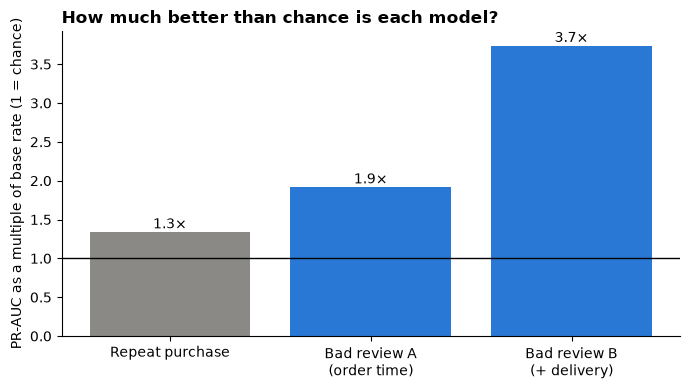

In [11]:
#How much better than chance is each model? These are the cross-validated PR-AUC values from your results, divided by each task’s base rate:
models = pd.DataFrame({
    "model": ["Repeat purchase", "Bad review A\n(order time)", "Bad review B\n(+ delivery)"],
    "multiple": [0.0258 / 0.0193, 0.2444 / 0.1276, 0.4767 / 0.1276],
})
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(models["model"], models["multiple"], color=[GRAY, BLUE, BLUE])
ax.axhline(1, color="black", lw=1)
for i, v in enumerate(models["multiple"]):
    ax.text(i, v + 0.05, f"{v:.1f}×", ha="center")
ax.set_ylabel("PR-AUC as a multiple of base rate (1 = chance)")
ax.set_title("How much better than chance is each model?", loc="left", fontweight="bold")
save("09_model_vs_chance.png")